In [1]:
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("../data/processed/customers_clean.csv")
pipeline = joblib.load("../models/customeriq_kmeans_pipeline.joblib")

FEATURES = ["Number_of_Orders", "Avg_Order_Value", "Days_Since_Last_Purchase",
            "Items_Per_Order", "Average_Rating", "Discount_Applied"]
df["Cluster"] = pipeline.predict(df[FEATURES])
df["Cluster"].value_counts().sort_index()


Cluster
0    13726
1    20911
2    11834
3    13529
Name: count, dtype: int64

In [2]:
money = df.groupby("Cluster").agg(customers=("Cluster", "size"),
                                  revenue=("Total_Spend", "sum"))
money["pct_of_customers"] = (money["customers"] / money["customers"].sum() * 100).round(1)
money["pct_of_revenue"] = (money["revenue"] / money["revenue"].sum() * 100).round(1)
money[["customers", "pct_of_customers", "pct_of_revenue"]]

,customers,pct_of_customers,pct_of_revenue
Cluster,,,
0,13726,22.9,2.0
1,20911,34.9,19.2
2,11834,19.7,63.2
3,13529,22.5,15.6


In [4]:
print(pd.crosstab(df["Cluster"], df["Gender"], normalize="index").round(2), "\n")
print(pd.crosstab(df["Cluster"], df["Satisfaction_Level"], normalize="index").round(2))

Gender   Female  Male  Other
Cluster                     
0          0.48  0.49   0.03
1          0.48  0.49   0.03
2          0.49  0.48   0.03
3          0.48  0.49   0.03 

Satisfaction_Level  High   Low  Medium
Cluster                               
0                   0.34  0.18    0.48
1                   0.25  0.26    0.49
2                   0.71  0.03    0.26
3                   0.25  0.27    0.48


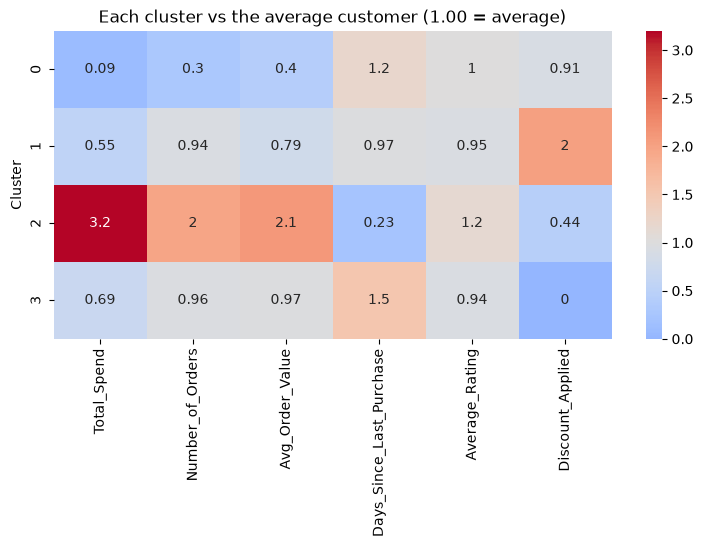

In [5]:
cols = ["Total_Spend", "Number_of_Orders", "Avg_Order_Value",
        "Days_Since_Last_Purchase", "Average_Rating", "Discount_Applied"]
relative = df.groupby("Cluster")[cols].mean() / df[cols].mean()

plt.figure(figsize=(9, 4))
sns.heatmap(relative.round(2), annot=True, cmap="coolwarm", center=1)
plt.title("Each cluster vs the average customer (1.00 = average)")
plt.savefig("../reports/figures/cluster_heatmap.png", dpi=150, bbox_inches="tight")
plt.show()

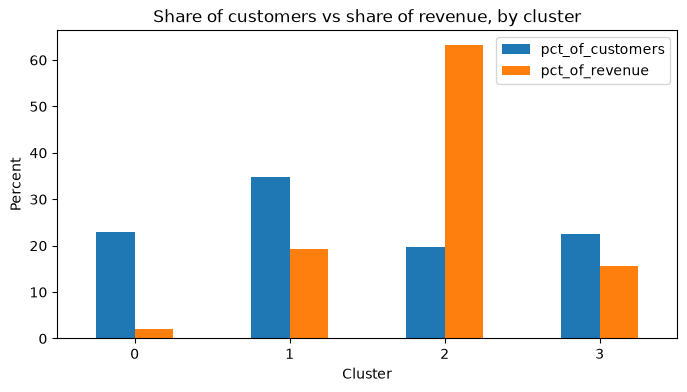

In [8]:
share = money[["pct_of_customers", "pct_of_revenue"]]
share.plot(kind="bar", figsize=(8, 4))
plt.title("Share of customers vs share of revenue, by cluster")
plt.xlabel("Cluster")
plt.ylabel("Percent")
plt.xticks(rotation=0)
plt.savefig("../reports/figures/customers_vs_revenue.png", dpi=150, bbox_inches="tight")
plt.show()

In [10]:
import json

SEGMENTS = {
    "2": {
        "name": "VIPS",
        "summary": "Highest spend, most frequent, most recent, happiest customers.",
        "strategy": "Protect and reward: loyalty perks, early access, personal service. No discounts needed.",
    },
    "3": {
        "name": "At-Risk Full-Price Buyers",
        "summary": "Good spenders who have gone quiet and never use discounts.",
        "strategy": "Win-back campaign: a personal message and new arrivals. Test a small incentive against none.",
    },
    "1": {
        "name": "Discount-Driven Regulars",
        "summary": "Regular buyers who always use a discount, with the lowest ratings.",
        "strategy": "Use bundles, basket minimums and loyalty points instead of blanket discounts.",
    },
    "0": {
        "name": "Occasional Low-Spenders",
        "summary": "Rare, small purchases and very low revenue.",
        "strategy": "Low-cost automated outreach. Aim to increase basket size.",
    },
}

with open("../models/segment_profiles.json", "w", encoding="utf-8") as f:
    json.dump(SEGMENTS, f, indent=2)

profile_table = df.groupby("Cluster")[
    ["Total_Spend", "Number_of_Orders", "Avg_Order_Value",
     "Days_Since_Last_Purchase", "Average_Rating", "Discount_Applied", "Items_Per_Order"]
].mean().round(2)
profile_table.to_csv("../models/cluster_profiles.csv")
print(profile_table)

         Total_Spend  Number_of_Orders  Avg_Order_Value  \
Cluster                                                   
0            3053.84              3.97           788.70   
1           19269.53             12.28          1535.07   
2          112243.35             25.83          4101.67   
3           24297.99             12.56          1897.11   

         Days_Since_Last_Purchase  Average_Rating  Discount_Applied  \
Cluster                                                               
0                           70.64            3.82              0.45   
1                           57.21            3.63              1.00   
2                           13.42            4.44              0.22   
3                           90.44            3.62              0.00   

         Items_Per_Order  
Cluster                   
0                   1.32  
1                   2.34  
2                   2.82  
3                   2.12  


## Cluster Names and Business Actions

*Names are my interpretation of each cluster's average behavior. The algorithm only produced the numbers 0 to 3.*

| Cluster | Name | Evidence (from cluster averages) | Recommended action |
|---|---|---|---|
| 2 | **VIP customers** | 19.7% of customers but 63.2% of revenue. Avg spend ₹112,243, 26 orders, ₹4,102 per visit, last purchase 13 days ago, rating 4.44, only 22% use a discount | Protect and reward: loyalty perks, early access, personal service. No discounts needed, since they already buy at full price |
| 3 | **At-Risk Full-Price Buyers** | 22.5% of customers, 15.6% of revenue. Avg spend ₹24,298, 12.6 orders, but 90 days since last purchase (longest) and 0% use discounts | Win-back campaign: a "we miss you" message, new arrivals, a personal reminder. Test a small incentive against no incentive before spending money |
| 1 | **Discount-Driven Regulars** | Largest group (34.9%), 19.2% of revenue. Avg spend ₹19,270, 12 orders, 100% use a discount, rating 3.63 (lowest) | Keep them engaged without deepening the habit: bundle offers, minimum-basket thresholds, loyalty points instead of blanket discounts |
| 0 | **Occasional Low-Spenders** | 22.9% of customers, only 2.0% of revenue. Avg spend ₹3,054, 4 orders, ₹789 per visit, 1.3 items per order | Low-cost automated outreach only (email, app notifications). Aim to raise basket size, such as "add one more item" offers |

**What these results do not show:**
- Cluster 1 *uses* discounts. The data cannot show that they *respond to* them, because we have no before-and-after information. An A/B test would be needed.
- Cluster 3 *looks like* customers who are fading. The model is not a churn model and gives no probability of leaving.
- The dataset is synthetic, so these are demonstrations of the method, not real business findings.